In [1]:
'''
seeing how close streaks are to each oother from their saved positions
'''

'\nseeing how close streaks are to each oother from their saved positions\n'

In [4]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
# import scipy.ndimage as snm


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
# import implantation_functions as imp
# from tensorflow import keras
import get_postage_stamps as gpsf
import fitting

# from scipy.ndimage import sobel
# from scipy.signal import find_peaks
import importlib
import random
from pathlib import Path
import re


In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
xy_file = xy_path+"ztf_20221020148032_000686_zg_c05_x_1.fits"
xys = fits.open(xy_file)
data = xys[1].data  

In [12]:
import pandas as pd
import numpy as np
from astropy.io import fits
import os
import random
from pathlib import Path
import re

# Set the path
xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"

# Get all FITS files in the directory
all_files = [f for f in os.listdir(xy_path) if f.endswith('.fits')]

# Target numbers
target_numbers = ['000686', '000640', '000449']

# Group files by number
files_by_number = {num: [] for num in target_numbers}

for filename in all_files:
    parts = filename.split('_')
    if len(parts) > 2:
        number = parts[2]
        if number in target_numbers:
            files_by_number[number].append(filename)

# Randomly select 1000 files from each number
selected_files = []
for number in target_numbers:
    available = len(files_by_number[number])
    n_to_select = min(1000, available)
    selected = random.sample(files_by_number[number], n_to_select)
    selected_files.extend(selected)
    print(f"Selected {n_to_select} files from number {number} (out of {available} available)")

print(f"\nProcessing {len(selected_files)} total files...")

# List to store all data
all_data = []

# Process each file
for i, filename in enumerate(selected_files):
    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(selected_files)} files...")
    
    try:
        # Extract the number (000686) and filter (zg) from filename
        parts = filename.split('_')
        number = parts[2]  # 000686, 000640, or 000449
        filter_band = parts[3]  # zg, zr, or zi
        
        # Open the FITS file
        filepath = os.path.join(xy_path, filename)
        with fits.open(filepath) as hdul:
            data = hdul[1].data
            
            # Extract X and Y coordinates
            x_coords = data['X']
            y_coords = data['Y']
            
            # Create entries for each coordinate
            for idx, (x, y) in enumerate(zip(x_coords, y_coords)):
                all_data.append({
                    'filename': filename,
                    'field': number,
                    'filter': filter_band,
                    'x': x,
                    'y': y,
                    'coordinate_index': idx
                })
    
    except Exception as e:
        print(f"Error processing {filename}: {e}")
        continue

# Create DataFrame
df = pd.DataFrame(all_data)

print(f"\nCreated DataFrame with {len(df)} total coordinates from {len(selected_files)} files")
print(f"DataFrame shape: {df.shape}")
print(f"\nFirst few rows:")
print(df.head(10))


Selected 192 files from number 000686 (out of 192 available)
Selected 192 files from number 000640 (out of 192 available)
Selected 128 files from number 000449 (out of 128 available)

Processing 512 total files...
Processed 100/512 files...
Processed 200/512 files...
Processed 300/512 files...
Processed 400/512 files...
Processed 500/512 files...

Created DataFrame with 25050 total coordinates from 512 files
DataFrame shape: (25050, 6)

First few rows:
                                    filename   field filter       x       y  \
0  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi  1058.0  1512.0   
1  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi  2014.0   125.0   
2  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi   665.0  1069.0   
3  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi  2877.0  1021.0   
4  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi  2185.0  1425.0   
5  ztf_20221020138241_000686_zi_c14_x_3.fits  000686     zi   700.0  

KeyError: 'number'

In [17]:
print(f"\nFiles per field:")
print(df.groupby('field')['filename'].nunique())
print(f"\nUnique filters: {df[df['field']=='000686']['filter'].unique()}")
print(f"\nDataFrame info:")
print(df.info())


Files per field:
field
000449    128
000640    192
000686    192
Name: filename, dtype: int64

Unique filters: ['zi' 'zg']

DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25050 entries, 0 to 25049
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   filename          25050 non-null  object 
 1   field             25050 non-null  object 
 2   filter            25050 non-null  object 
 3   x                 25050 non-null  float64
 4   y                 25050 non-null  float64
 5   coordinate_index  25050 non-null  int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 1.1+ MB
None


(array([13608.,     0.,     0.,     0.,     0.,  9690.,     0.,     0.,
            0.,  1752.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

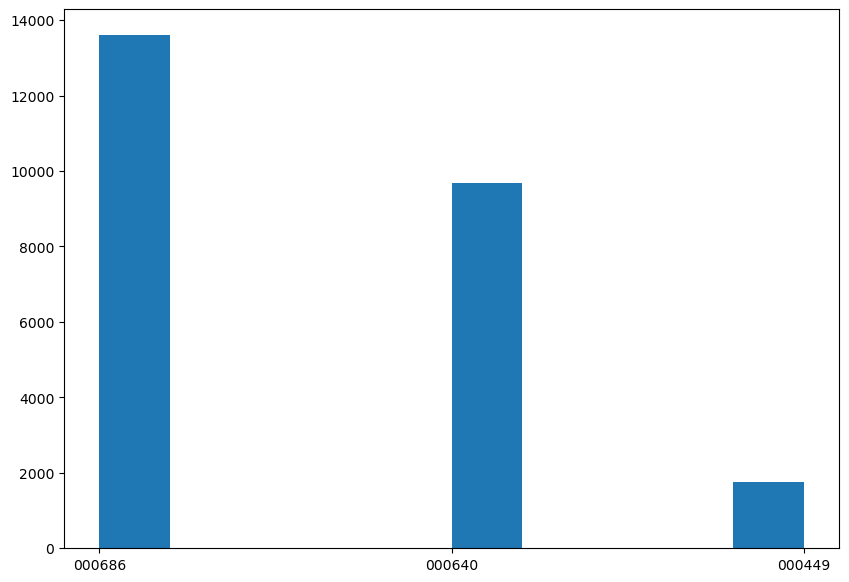

In [14]:
plt.hist(df['field'])

In [41]:
# Count how many X values are within 5 of other X values from the same file
# Group by number and filename, then count for each file
X_THRESHOLD = 8

print(f"\n{'='*60}")
print(f"ANALYZING X COORDINATES WITHIN {X_THRESHOLD} OF EACH OTHER")
print(f"{'='*60}")


target_fields = ['000686', '000640', '000449']

results = []

for field in target_fields:
    print(f"\nProcessing field {field}...")
    
    # Get data for this field
    # df_coord = df[df['coordinate_index']<10]
    df_coord = df
    df_field = df_coord[df_coord['field'] == field]
    
    # Group by filename
    for filename, group in df_field.groupby('filename'):
        x_values = group['x'].values
        
        # For each X value, count how many other X values are within threshold
        count = 0
        for i, x in enumerate(x_values):
            # Count how many other X values (excluding itself) are within threshold
            distances = np.abs(x_values - x)
            # Exclude the point itself (distance = 0) and count those within threshold
            within_threshold = np.sum((distances > 0) & (distances <= X_THRESHOLD))
            if within_threshold > 0:
                count += 1
        
        results.append({
            'field': field,
            'filename': filename,
            'total_coordinates': len(x_values),
            'x_within_threshold': count
        })

# Create results DataFrame
results_df = pd.DataFrame(results)

print("\n" + "="*60)
print(f"SUMMARY BY FIELD (threshold = {X_THRESHOLD})")
print("="*60)

for field in target_fields:
    df_fld = results_df[results_df['field'] == field]
    total_x_within = df_fld['x_within_threshold'].sum()
    total_coords = df_fld['total_coordinates'].sum()
    mean_per_file = df_fld['x_within_threshold'].mean()
    
    print(f"\nField {field}:")
    print(f"  Total X values within {X_THRESHOLD} of another X: {total_x_within:,}")
    print(f"  Total coordinates: {total_coords:,}")
    print(f"  Percentage: {100 * total_x_within / total_coords:.2f}%")
    print(f"  Mean per file: {mean_per_file:.2f}")

print("\n" + "="*60)
print("\nFirst few rows of results:")
print(results_df.head(10))


ANALYZING X COORDINATES WITHIN 8 OF EACH OTHER

Processing field 000686...

Processing field 000640...

Processing field 000449...

SUMMARY BY FIELD (threshold = 8)

Field 000686:
  Total X values within 8 of another X: 722
  Total coordinates: 13,608
  Percentage: 5.31%
  Mean per file: 3.76

Field 000640:
  Total X values within 8 of another X: 362
  Total coordinates: 9,690
  Percentage: 3.74%
  Mean per file: 1.89

Field 000449:
  Total X values within 8 of another X: 26
  Total coordinates: 1,752
  Percentage: 1.48%
  Mean per file: 0.20


First few rows of results:
    field                                   filename  total_coordinates  \
0  000686  ztf_20221020138241_000686_zi_c01_x_1.fits                 63   
1  000686  ztf_20221020138241_000686_zi_c01_x_2.fits                 79   
2  000686  ztf_20221020138241_000686_zi_c01_x_3.fits                 69   
3  000686  ztf_20221020138241_000686_zi_c01_x_4.fits                 54   
4  000686  ztf_20221020138241_000686_zi_c02_x_

Summary of looking into the proximity of streaks to each other based on the saved positions of the streaks:

Due to my detection criteria, no streaks are detected <8 pixels of each other - these are considered 'the same streak'. 

Looking at 8-11 pixels (largest aperture), 20% of streaks for the Galactic field and 5% of the streaks for the extragalactic field are within 11 pixels.

However, if we only look at the 25 brightest streaks in each image (that's the limit I used for my transient candidates), its only 6.85% of streaks that are within 11 pixels of another streak in the Galactic field (still 5% for extragalactic)

If I look at the top ten streaks in each image (like for training data), 3% are within 11 pixels in the Galatic field, 4.8% in the extragalactic

waiit, forgot to include the central pixel varying by up to 3...

Due to my detection criteria, no streaks are detected <=8 pixels of each other - these are considered ‘the same streak’. Unfortunately that would be everything at aperture 5 + streak center moving by 3.

Looking at 8-10 pixels (half-aperture 3 plus center moving by 3), 15% of streaks for the Galactic field and 4% of the streaks for the extragalactic field are within 10 pixels.

However, if we only look at the 25 brightest streaks in each image (that’s the limit I used for my transient candidates), its only 5% of streaks that are within 10 pixels of another streak in the Galactic field (still 4% for extragalactic)

In [58]:
# ============================================================================
# PROXIMITY ANALYSIS ACROSS MULTIPLE THRESHOLDS
# ============================================================================

print(f"\n{'='*60}")
print(f"ANALYZING X COORDINATES ACROSS MULTIPLE THRESHOLDS")
print(f"{'='*60}")

# Define the range of thresholds to test
thresholds = range(8, 19)  # 8 to 18 inclusive

# Dictionary to store results
threshold_results = {field: {} for field in target_fields}

for threshold in thresholds:
    print(f"\nProcessing threshold {threshold}...")
    
    for field in target_fields:
        # Get data for this field
        df_coord = df[df['coordinate_index']<25]
        df_field = df_coord[df_coord['field'] == field]
        
        # Count total X values within threshold across all files
        total_count = 0
        
        # Group by filename
        for filename, group in df_field.groupby('filename'):
            x_values = group['x'].values
            
            # For each X value, check if it's within threshold of another
            for i, x in enumerate(x_values):
                distances = np.abs(x_values - x)
                within_threshold = np.sum((distances > 0) & (distances <= threshold))
                if within_threshold > 0:
                    total_count += 1
        
        threshold_results[field][threshold] = total_count

# Create DataFrame with fields as rows and thresholds as columns
summary_df25 = pd.DataFrame(threshold_results).T
summary_df25.index.name = 'field'

print("\n" + "="*60)
print("RESULTS: X VALUES WITHIN THRESHOLD")
print("="*60)
print(summary_df25)

# Also create a percentage version
print("\n" + "="*60)
print("RESULTS: PERCENTAGE OF X VALUES WITHIN THRESHOLD")
print("="*60)

# Calculate total coordinates per field
total_coords_per_field = df.groupby('field')['x'].count()

percentage_df25 = summary_df25.copy()
for field in target_fields:
    percentage_df25.loc[field] = (summary_df25.loc[field] / total_coords_per_field[field] * 100).round(2)

print(percentage_df25)

# Optional: Save to CSV
# summary_df.to_csv('proximity_counts.csv')
# percentage_df.to_csv('proximity_percentages.csv')


ANALYZING X COORDINATES ACROSS MULTIPLE THRESHOLDS

Processing threshold 8...

Processing threshold 9...

Processing threshold 10...

Processing threshold 11...

Processing threshold 12...

Processing threshold 13...

Processing threshold 14...

Processing threshold 15...

Processing threshold 16...

Processing threshold 17...

Processing threshold 18...

RESULTS: X VALUES WITHIN THRESHOLD
        8    9    10   11   12   13   14   15   16   17   18
field                                                       
000686  76  143  228  329  394  458  510  575  645  698  752
000640  66  117  194  278  374  422  485  564  626  685  738
000449  26   44   72   88  100  114  131  143  162  176  193

RESULTS: PERCENTAGE OF X VALUES WITHIN THRESHOLD
          8     9     10    11    12    13    14    15    16     17     18
field                                                                     
000686  0.56  1.05  1.68  2.42  2.90  3.37  3.75  4.23  4.74   5.13   5.53
000640  0.68  1.21  2.00  

In [59]:
percentage_df25

,8,9,10,11,12,13,14,15,16,17,18
field,,,,,,,,,,,
000686,0.56,1.05,1.68,2.42,2.90,3.37,3.75,4.23,4.74,5.13,5.53
000640,0.68,1.21,2.00,2.87,3.86,4.36,5.01,5.82,6.46,7.07,7.62
000449,1.48,2.51,4.11,5.02,5.71,6.51,7.48,8.16,9.25,10.05,11.02


In [51]:
percentage_df.T.iloc[0]

field
000686    5.31
000640    3.74
000449    1.48
Name: 8, dtype: float64

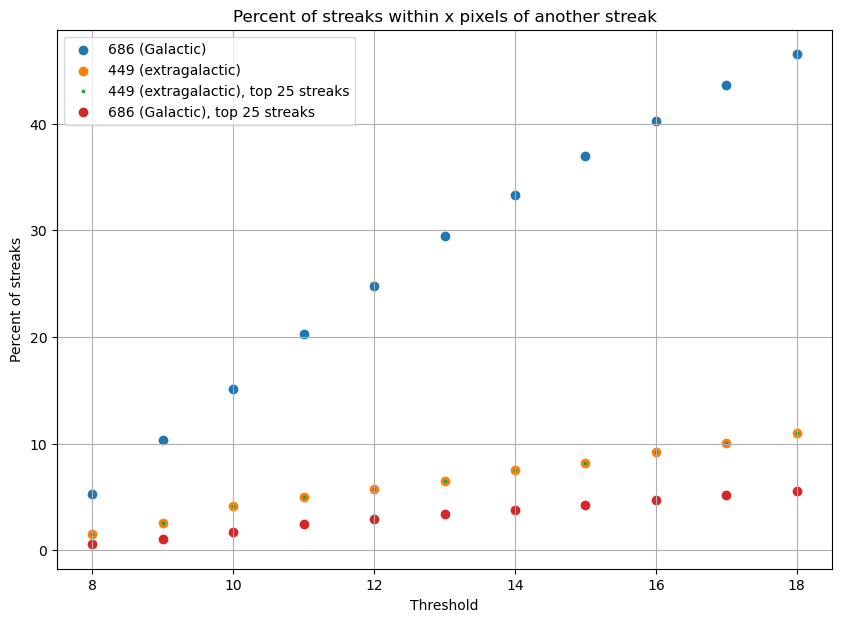

In [66]:
plt.scatter(thresholds,percentage_df.T['000686'], label='686 (Galactic)')
plt.scatter(thresholds,percentage_df.T['000449'], label='449 (extragalactic)')

plt.xlabel("Threshold")
plt.ylabel("Percent of streaks")
plt.title("Percent of streaks within x pixels of another streak")


plt.scatter(thresholds,percentage_df25.T['000449'], s=3,label='449 (extragalactic), top 25 streaks')
plt.scatter(thresholds,percentage_df25.T['000686'], label='686 (Galactic), top 25 streaks')
plt.legend()
plt.grid()